# Analiza braków danych

Celem notatnika jest sprawdzenie kompletności danych potrzebnych do analizy czterech pytań badawczych dotyczących wykorzystania AI przez respondentów:

- P1: Czy częstotliwość korzystania z narzędzi AI jest związana z doświadczeniem zawodowym?
- P2: Jakie zadania respondenci wykonują z pomocą AI i jak wiąże się to z ich rolą zawodową?
- P3: Czy zaufanie do AI wiąże się z częstotliwością korzystania z niej, wiekiem i doświadczeniem zawodowym?
- P4: Jak ocena wpływu AI na wykonywane zadania wiąże się z satysfakcją z jej wykorzystania?

Do każdego pytania przypisano zmienne uwzględnione w analizie brakujących danych. Dodatkowo wybrano zmienne pomocnicze, które pomagają w sprawdzeniu kompletności odpowiedzi.

In [42]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

df = pd.read_csv(
    ROOT / "data/raw/survey_results_public.csv",
    low_memory=False,
)

schema = pd.read_csv(
    ROOT / "data/raw/survey_results_schema.csv"
)

# P1 – częstotliwość używania AI a doświadczenie zawodowe
p1_variables = [
    "WorkExp",
    "AIFreq_1",
    "AIFreq_2",
    "AIFreq_3",
    "AIFreq_4"
]

# P2 – zadania wykonywane z pomocą AI a rola zawodowa
p2_variables = [
    "Role",
    "AIWorkCurrentlyUse"
]

# P3 – zaufanie do AI a częstotliwość używania, wiek i staż
p3_variables = [
    "AITrust",
    "Age",
    "WorkExp",
    "AIFreq_1",
    "AIFreq_2",
    "AIFreq_3",
    "AIFreq_4"
]

# P4 – użyteczność AI a satysfakcja
p4_variables = [
    "AIImpact_1",
    "AIImpact_2",
    "AIImpact_3",
    "AIImpact_4",
    "AIImpact_5",
    "AIImpact_6",
    "AIImpact_7",
    "AISat_1",
    "AISat_2",
    "AISat_3",
    "AISat_4",
    "AISat_5",
    "AISat_6",
    "AISat_7"
]

# Zmienne pomocnicze
control_variables = [
    "AISelect"
]

# Wszystkie zmienne do analizy braków
variables = list(dict.fromkeys(
    p1_variables + p2_variables +
    p3_variables + p4_variables +
    control_variables
))

print("P1:", len(p1_variables), "zmiennych")
print("P2:", len(p2_variables), "zmiennych")
print("P3:", len(p3_variables), "zmiennych")
print("P4:", len(p4_variables), "zmiennych")
print("Pomocnicze:", len(control_variables), "zmienna")
print("Łącznie:", len(variables), "unikalnych zmiennych")

P1: 5 zmiennych
P2: 2 zmiennych
P3: 7 zmiennych
P4: 14 zmiennych
Pomocnicze: 1 zmienna
Łącznie: 24 unikalnych zmiennych


## 1. Ogólna analiza braków danych

W pierwszej kolejności sprawdzono liczbę i procent brakujących odpowiedzi w każdej z wybranych zmiennych. Procent braków obliczono względem wszystkich 30 903 respondentów.

In [12]:
analysis_variables = [var for var in variables if var != "ResponseId"]

missing_summary = pd.DataFrame({
    "Liczba braków": df[analysis_variables].isna().sum(),
    "Liczba odpowiedzi": df[analysis_variables].notna().sum(),
    "Procent braków": df[analysis_variables].isna().mean() * 100
}).round(2)

missing_summary

,Liczba braków,Liczba odpowiedzi,Procent braków
WorkExp,6296,24607,20.37
AIFreq_1,19472,11431,63.01
AIFreq_2,20051,10852,64.88
AIFreq_3,26376,4527,85.35
AIFreq_4,27830,3073,90.06
Role,5136,25767,16.62
AIWorkCurrentlyUse,19693,11210,63.73
AITrust,16599,14304,53.71
Age,0,30903,0.00
AIImpact_1,18367,12536,59.43


W tabeli widoczna jest różnica w kompletności odpowiedzi między poszczególnymi zmiennymi. Najwięcej braków występuje w zmiennych `AIFreq_1–AIFreq_4`, które odnoszą się do częstotliwości korzystania z różnych rodzajów narzędzi AI. Wysoki odsetek braków może wynikać ze sposobu skonstruowania pytania macierzowego, w którym każda kategoria narzędzi stanowi osobną pozycję do oceny.

Dla lepszego porównania poziomu braków danych przedstawiono je również na wykresie. Zmienne zostały uporządkowane według procentu brakujących odpowiedzi, co pozwala szybko zauważyć różnice w ich kompletności.

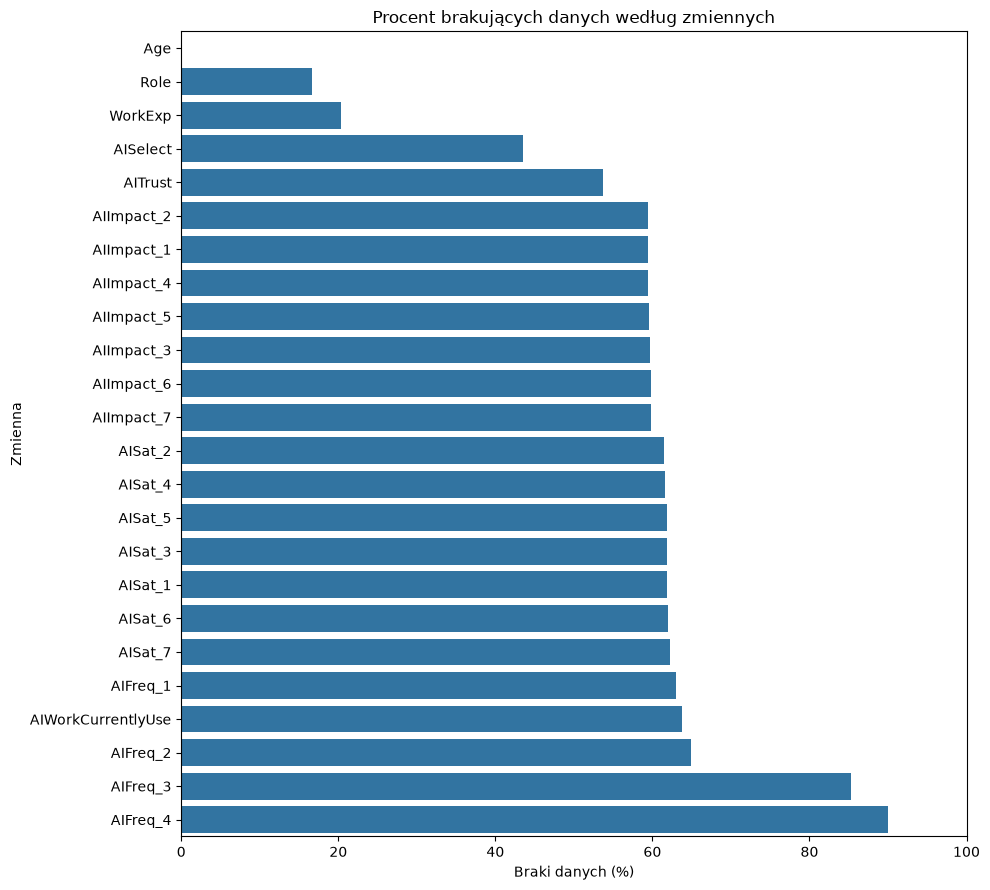

In [11]:
missing_plot = missing_summary.reset_index()

missing_plot = missing_plot.sort_values(
    "Procent braków",
    ascending=True
)

plt.figure(figsize=(10, 9))

sns.barplot(
    data=missing_plot,
    x="Procent braków",
    y="index"
)

plt.title("Procent brakujących danych według zmiennych")
plt.xlabel("Braki danych (%)")
plt.ylabel("Zmienna")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## 2. Analiza braków danych w zależności od odpowiedzi respondentów

Sama liczba brakujących wartości nie wyjaśnia, dlaczego respondenci nie odpowiedzieli na dane pytanie. Następna część dotyczy sprawdzenia, czy występowanie braków może być powiązane z deklarowanym korzystaniem z narzędzi AI oraz sposobem przechodzenia przez pytania ankiety.

Celem jest odróżnienie sytuacji, w których brak odpowiedzi może wynikać z logiki ankiety, od przypadków, w których respondent pominął pytanie mimo deklarowanego korzystania z danego narzędzia.

### 2.1 Deklarowane korzystanie z narzędzi AI

W zmiennej `AISelect` sprawdzono deklaracje respondentów dotyczące korzystania z narzędzi AI. Określono liczbę i procent odpowiedzi, uwzględniając również osoby, które nie udzieliły odpowiedzi na to pytanie.

In [13]:
print("Rozkład odpowiedzi AISelect:")
ai_select_summary = pd.DataFrame({
    "Liczba odpowiedzi": df["AISelect"].value_counts(dropna=False),
    "Procent odpowiedzi": (
        df["AISelect"].value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})

ai_select_summary.index.name = "Deklarowane korzystanie z AI"

display(ai_select_summary)

Rozkład odpowiedzi AISelect:


,Liczba odpowiedzi,Procent odpowiedzi
Deklarowane korzystanie z AI,,
NaN,13439,43.49
AI coding assistants or coding agents;General-purpose AI chat tools,3966,12.83
I don’t use AI tools,2907,9.41
General-purpose AI chat tools,2390,7.73
AI coding assistants or coding agents,2337,7.56
AI agents or automated workflows;AI coding assistants or coding agents;General-purpose AI chat tools,1919,6.21
AI agents or automated workflows;AI coding assistants or coding agents;General-purpose AI chat tools;Internal AI tools built by my company,1612,5.22
AI coding assistants or coding agents;General-purpose AI chat tools;Internal AI tools built by my company,650,2.10
AI agents or automated workflows;AI coding assistants or coding agents,530,1.72


### 2.2. Zgodność odpowiedzi dotyczących korzystania z AI i częstotliwości jej używania

Wśród respondentów deklarujących korzystanie z narzędzi AI sprawdzono zgodność odpowiedzi dotyczących wyboru poszczególnych narzędzi (`AISelect`) z deklarowaną częstotliwością ich używania (`AIFreq_1–AIFreq_4`). Na tej podstawie określono, czy odpowiedzi na oba pytania były kompletne i zgodne.

In [43]:
tool_patterns = {
    "AIFreq_1: Asystenci kodowania AI": ("AIFreq_1", "AI coding assistants"),
    "AIFreq_2: Czaty AI ogólnego przeznaczenia": ("AIFreq_2", "General-purpose AI chat tools"),
    "AIFreq_3: Agenci AI i automatyzacje": ("AIFreq_3", "AI agents"),
    "AIFreq_4: Wewnętrzne narzędzia AI firmy": ("AIFreq_4", "Internal AI tools")
}

ai_select = df["AISelect"].fillna("")
results = []

for tool_name, (col, pattern) in tool_patterns.items():
    selected = ai_select.str.contains(pattern, case=False)

    results.append({
        "Rodzaj narzędzia": tool_name,
        "Zaznaczyli narzędzie w AISelect": selected.sum(),
        "Mają odpowiedź AIFreq": df.loc[selected, col].notna().sum(),
        "Brak odpowiedzi AIFreq": df.loc[selected, col].isna().sum(),
        "Nie zaznaczyli narzędzia": (~selected).sum(),
        "Mają odpowiedź mimo niezaznaczenia": df.loc[~selected, col].notna().sum()
    })

ai_consistency = pd.DataFrame(results)
display(ai_consistency)

,Rodzaj narzędzia,Zaznaczyli narzędzie w AISelect,Mają odpowiedź AIFreq,Brak odpowiedzi AIFreq,Nie zaznaczyli narzędzia,Mają odpowiedź mimo niezaznaczenia
0,AIFreq_1: Asystenci kodowania AI,11509,11431,78,19394,0
1,AIFreq_2: Czaty AI ogólnego przeznaczenia,10920,10852,68,19983,0
2,AIFreq_3: Agenci AI i automatyzacje,4582,4527,55,26321,0
3,AIFreq_4: Wewnętrzne narzędzia AI firmy,3115,3073,42,27788,0


In [44]:
ai_select = df["AISelect"].fillna("")

no_ai = ai_select.str.contains(
    "I don’t use AI tools",
    case=False,
    na=False
)

selected_tools = ai_select.str.contains(
    "AI coding assistants|General-purpose AI chat tools|AI agents|Internal AI tools",
    case=False,
    na=False
)

contradictory = no_ai & selected_tools

print("Liczba niespójnych odpowiedzi:", contradictory.sum())

Liczba niespójnych odpowiedzi: 96


Wyniki pokazują, że większość respondentów, którzy zadeklarowali korzystanie z danego narzędzia AI, udzieliła również odpowiedzi dotyczącej częstotliwości jego używania. Braki w tej grupie są niewielkie i wynoszą około 0,6–1,4%.

Może to oznaczać, że duża część braków w zmiennych `AIFreq_1`–`AIFreq_4` dotyczy osób, które nie wskazały danego narzędzia w pytaniu `AISelect`. Samo zestawienie odpowiedzi nie pozwala jednak jednoznacznie ustalić przyczyny tych braków.

### 2.3. Kompletność danych wsród osób korzystających z narzędzi AI

Wśród respondentów deklarujących korzystanie z poszczególnych narzędzi AI sprawdzono braki odpowiedzi dotyczące doświadczenia zawodowego (`WorkExp`) oraz częstotliwości korzystania z danego narzędzia (`AIFreq_1–AIFreq_4`). Na tej podstawie określono liczbę osób, które udzieliły kompletnych odpowiedzi potrzebnych do analizy pytania badawczego P1.

In [23]:
tool_patterns = {
    "AIFreq_1: Asystenci kodowania AI": ("AIFreq_1", "AI coding assistants"),
    "AIFreq_2: Czaty AI ogólnego przeznaczenia": ("AIFreq_2", "General-purpose AI chat tools"),
    "AIFreq_3: Agenci AI i automatyzacje": ("AIFreq_3", "AI agents"),
    "AIFreq_4: Wewnętrzne narzędzia AI firmy": ("AIFreq_4", "Internal AI tools")
}

ai_select = df["AISelect"].fillna("")

results = []

for tool_name, (col, pattern) in tool_patterns.items():
    selected = ai_select.str.contains(pattern, case=False, na=False)

    results.append({
        "Zmienna": tool_name,
        "Osoby deklarujące korzystanie": selected.sum(),
        "Brak WorkExp": df.loc[selected, "WorkExp"].isna().sum(),
        "Brak AIFreq mimo wskazania narzędzia": df.loc[selected, col].isna().sum(),
        "Kompletne odpowiedzi": (
            selected
            & df["WorkExp"].notna()
            & df[col].notna()
        ).sum()
    })

p1_final_check = pd.DataFrame(results)
display(p1_final_check)

,Zmienna,Osoby deklarujące korzystanie,Brak WorkExp,Brak AIFreq mimo wskazania narzędzia,Kompletne odpowiedzi
0,AIFreq_1: Asystenci kodowania AI,11509,345,78,11099
1,AIFreq_2: Czaty AI ogólnego przeznaczenia,10920,495,68,10369
2,AIFreq_3: Agenci AI i automatyzacje,4582,111,55,4422
3,AIFreq_4: Wewnętrzne narzędzia AI firmy,3115,41,42,3038


Wyniki wskazują, że wśród osób deklarujących korzystanie z poszczególnych narzędzi AI braki w odpowiedziach dotyczą niewielkiej części respondentów. Dotyczy to zarówno doświadczenia zawodowego (`WorkExp`), jak i częstotliwości korzystania z danego narzędzia (`AIFreq_1–AIFreq_4`). Liczba kompletnych odpowiedzi wynosi od 11 099 dla `AIFreq_1` do 3 038 dla `AIFreq_4`. 

### 2.4. Braki danych w zmiennych dotyczących roli zawodowej i wykorzystania AI

Wśród respondentów podzielonych na podstawie odpowiedzi w zmiennej `AISelect` sprawdzono braki danych dotyczące roli zawodowej (`Role`) oraz wykorzystywania AI w pracy (`AIWorkCurrentlyUse`). Pozwoliło to porównać kompletność odpowiedzi w tych grupach i ocenić, czy występują między nimi różnice.

In [24]:
df["AISelect_status"] = np.select(
    [
        df["AISelect"].isna(),
        df["AISelect"].str.contains("I don’t use AI tools", na=False)
    ],
    [
        "Brak odpowiedzi AISelect",
        "Zawiera deklarację niekorzystania z AI"
    ],
    default="Wskazano inne odpowiedzi"
)

p2_missing_analysis = df.groupby("AISelect_status").agg(
    Liczba_osob=("ResponseId", "count"),
    Braki_Role=("Role", lambda x: x.isna().sum()),
    Braki_AIWorkCurrentlyUse=("AIWorkCurrentlyUse", lambda x: x.isna().sum())
)

display(p2_missing_analysis)

,Liczba_osob,Braki_Role,Braki_AIWorkCurrentlyUse
AISelect_status,,,
Brak odpowiedzi AISelect,13439,5056,13439
Wskazano inne odpowiedzi,14461,34,3297
Zawiera deklarację niekorzystania z AI,3003,46,2957


Wyniki wskazują na wyraźne współwystępowanie braków w zmiennych `AISelect` i `AIWorkCurrentlyUse`. Wśród respondentów, którzy nie udzielili odpowiedzi na pytanie `AISelect`, brakuje również wszystkich odpowiedzi dotyczących aktualnego wykorzystania AI w pracy.

W grupie respondentów, którzy wskazali inne odpowiedzi w `AISelect`, brak odpowiedzi w `AIWorkCurrentlyUse` dotyczy 3 297 osób. W grupie zawierającej deklarację niekorzystania z AI braki w tej zmiennej występują u 2 957 osób.

Braki w zmiennej `Role` występują w każdej z grup, jednak ich odsetek jest szczególnie wysoki wśród osób, które nie odpowiedziały na pytanie dotyczące `AISelect`.

### 2.5. Braki danych w zmiennej dotyczącej zaufania do AI

Wśród respondentów podzielonych na podstawie odpowiedzi w zmiennej `AISelect` sprawdzono również braki danych dotyczące zaufania do AI (`AITrust`). Wyniki pozwoliły na określenie, czy liczba brakujących odpowiedzi dotyczących zaufania do AI różni się w zależności od deklaracji respondentów dotyczących korzystania z narzędzi AI.

In [25]:
p3_missing_analysis = df.groupby("AISelect_status").agg(
    Liczba_osob=("ResponseId", "count"),
    Braki_AITrust=("AITrust", lambda x: x.isna().sum())
)

p3_missing_analysis["Procent_brakow_AITrust"] = (
    p3_missing_analysis["Braki_AITrust"]
    / p3_missing_analysis["Liczba_osob"] * 100
).round(2)

display(p3_missing_analysis)

,Liczba_osob,Braki_AITrust,Procent_brakow_AITrust
AISelect_status,,,
Brak odpowiedzi AISelect,13439,13439,100.00
Wskazano inne odpowiedzi,14461,252,1.74
Zawiera deklarację niekorzystania z AI,3003,2908,96.84


Wyniki pokazują wyraźne różnice w kompletności odpowiedzi dotyczących zaufania do AI między grupami respondentów. Wśród osób, które nie odpowiedziały na pytanie `AISelect`, braki w `AITrust` wynoszą 100%, a wśród deklarujących niekorzystanie z AI 96,84%. W pozostałej grupie odsetek braków wynosi jedynie 1,74%.

Różnice te sugerują, że braki w `AITrust` mogą być związane z deklaracjami dotyczącymi korzystania z AI lub konstrukcją ankiety.

### 2.6. Współwystępowanie braków w ocenach wpływu AI i satysfakcji

Wśród respondentów sprawdzono braki odpowiedzi dotyczące wpływu AI na wykonywane zadania (`AIImpact_1–AIImpact_7`) oraz satysfakcji z wykorzystania AI (`AISat_1–AISat_7`). Pozwoli to porównać występowanie braków w obu grupach zmiennych i ocenić, czy odpowiedzi na te pytania są ze sobą powiązane.

In [47]:
p4_missing_patterns = []

for i in range(1, 8):
    impact = df[f"AIImpact_{i}"].isna()
    sat = df[f"AISat_{i}"].isna()

    p4_missing_patterns.append({
        "Para zmiennych": f"AIImpact_{i} / AISat_{i}",
        "Braki w obu": (impact & sat).sum(),
        "Brak tylko AIImpact": (impact & ~sat).sum(),
        "Brak tylko AISat": (~impact & sat).sum(),
        "Braków w żadnej": (~impact & ~sat).sum()
    })

p4_missing_patterns = pd.DataFrame(p4_missing_patterns)
display(p4_missing_patterns)

,Para zmiennych,Braki w obu,Brak tylko AIImpact,Brak tylko AISat,Braków w żadnej
0,AIImpact_1 / AISat_1,18292,75,843,11693
1,AIImpact_2 / AISat_2,18270,87,712,11834
2,AIImpact_3 / AISat_3,18353,101,782,11667
3,AIImpact_4 / AISat_4,18287,88,755,11773
4,AIImpact_5 / AISat_5,18342,78,773,11710
5,AIImpact_6 / AISat_6,18394,81,768,11660
6,AIImpact_7 / AISat_7,18420,69,798,11616


Braki odpowiedzi dotyczące wpływu AI i satysfakcji najczęściej występują jednocześnie. Rzadziej brakuje tylko jednej z ocen, przy czym częściej pomijane są odpowiedzi dotyczące satysfakcji (`AISat`) niż wpływu AI (`AIImpact`).

Wyniki wskazują, że kompletność odpowiedzi na oba pytania jest ze sobą powiązana. 

## 3. Kompletność danych w odniesieniu do pytań badawczych

Dla każdego pytania badawczego sprawdzono liczbę respondentów, którzy udzielili odpowiedzi na wszystkie przypisane do niego zmienne. Na tej podstawie określono liczbę i procent kompletnych obserwacji w stosunku do całego zbioru danych. Wyniki pokazują, jaka część respondentów może zostać uwzględniona w dalszych analizach.

### 3.1. P1 – Częstotliwość korzystania z AI a doświadczenie zawodowe

Dla pytania badawczego P1 sprawdzono kompletność odpowiedzi dotyczących doświadczenia zawodowego (`WorkExp`) i częstotliwości korzystania z poszczególnych narzędzi AI (`AIFreq_1–AIFreq_4`). Liczbę kompletnych obserwacji obliczono osobno dla każdego narzędzia. Uwzględniono respondentów, którzy udzielili odpowiedzi na oba pytania.

In [34]:
print("Kompletne obserwacje dla P1:")

for var in p1_variables[1:]:
    count = df[["WorkExp", var]].dropna().shape[0]
    percentage = round(count / len(df) * 100, 2)

    print(f"{var}: {count} ({percentage}%)")


Kompletne obserwacje dla P1:
AIFreq_1: 11099 (35.92%)
AIFreq_2: 10369 (33.55%)
AIFreq_3: 4422 (14.31%)
AIFreq_4: 3038 (9.83%)


### 3.2. P2 - Wykorzystywanie AI w pracy a rola zawodowa

Dla pytania badawczego P2 sprawdzono kompletność odpowiedzi dotyczących roli zawodowej respondentów (`Role`) oraz zadań wykonywanych z wykorzystaniem AI (`AIWorkCurrentlyUse`). Za kompletne uznano obserwacje, w których respondent udzielił odpowiedzi na obie zmienne. Na tej podstawie określono liczbę osób, które mogą zostać uwzględnione w analizie P2.

In [28]:
p2_complete = df[["Role", "AIWorkCurrentlyUse"]].dropna()

print("Kompletne obserwacje dla P2:", len(p2_complete))
print("Procent kompletnych obserwacji:", round(len(p2_complete) / len(df) * 100, 2), "%")

Kompletne obserwacje dla P2: 11197
Procent kompletnych obserwacji: 36.23 %


### 3.3. P3 - Zaufanie do AI a częstotliwość korzystania, wiek i doświadczenie zawodowe

Dla pytania badawczego P3 sprawdzono kompletność odpowiedzi dotyczących zaufania do AI (`AITrust`), wieku (`Age`), doświadczenia zawodowego (`WorkExp`) oraz częstotliwości korzystania z poszczególnych narzędzi AI (`AIFreq_1–AIFreq_4`). Liczbę kompletnych obserwacji obliczono osobno dla każdego narzędzia. Uwzględniono respondentów, którzy udzielili odpowiedzi na wszystkie zmienne wymagane w danym zestawieniu

In [36]:
print("Kompletne obserwacje dla P3:")

for var in p3_variables[3:]:
    count = df[["AITrust", "Age", "WorkExp", var]].dropna().shape[0]
    percentage = round(count / len(df) * 100, 2)

    print(f"{var}: {count} ({percentage}%)")

Kompletne obserwacje dla P3:
AIFreq_1: 10971 (35.5%)
AIFreq_2: 10249 (33.17%)
AIFreq_3: 4371 (14.14%)
AIFreq_4: 2999 (9.7%)


### 3.4. P4 - Wpływ AI na wykonywane zadania a satysfakcja z jego wykorzystania

Dla pytania badawczego P4 sprawdzono kompletność odpowiedzi dotyczących wpływu AI na wykonywane zadania (`AIImpact_1–AIImpact_7`) oraz satysfakcji z wykorzystania AI (`AISat_1–AISat_7`). Liczbę kompletnych obserwacji obliczono osobno dla każdej pary zmiennych. Uwzględniono respondentów, którzy udzielili odpowiedzi zarówno na pytanie o wpływ AI, jak i o satysfakcję z jego wykorzystania.

In [39]:
print("Kompletne obserwacje dla P4:")

for i in range(1, 8):
    count = df[[f"AIImpact_{i}", f"AISat_{i}"]].dropna().shape[0]
    percentage = round(count / len(df) * 100, 2)

    print(f"AIImpact_{i} i AISat_{i}: {count} ({percentage}%)")

Kompletne obserwacje dla P4:
AIImpact_1 i AISat_1: 11693 (37.84%)
AIImpact_2 i AISat_2: 11834 (38.29%)
AIImpact_3 i AISat_3: 11667 (37.75%)
AIImpact_4 i AISat_4: 11773 (38.1%)
AIImpact_5 i AISat_5: 11710 (37.89%)
AIImpact_6 i AISat_6: 11660 (37.73%)
AIImpact_7 i AISat_7: 11616 (37.59%)


## 4. Rekomendacje dotyczące postępowania z brakami danych

Na podstawie przeprowadzonej analizy określono zalecenia dotyczące przygotowania danych do dalszych analiz. Uwzględniono możliwe przyczyny braków, ich wpływ na liczebność próby oraz specyfikę poszczególnych pytań badawczych.

### 4.1. Możliwe przyczyny braków danych

Nie wszystkie braki danych należy traktować jako pominięcie pytania przez respondenta. W przypadku `AIFreq_1–AIFreq_4` brak odpowiedzi może wynikać z niezaznaczenia danego narzędzia w `AISelect`. Z kolei brak w `AIWorkCurrentlyUse` wymaga sprawdzenia zasad przechodzenia przez ankietę. W przypadku `WorkExp` należy uwzględnić możliwość, że respondent nie posiada doświadczenia zawodowego.

### 4.2. Kontrola niespójnych odpowiedzi

Wykryte niespójne deklaracje w zmiennej `AISelect` powinny zostać uwzględnione podczas przygotowania danych. Dotyczy to respondentów, którzy jednocześnie zadeklarowali niekorzystanie z narzędzi AI i wskazali co najmniej jedno z nich. Takie obserwacje należy oznaczyć i sprawdzić przed dalszą analizą. Nie powinno się automatycznie usuwać tych odpowiedzi ani samodzielnie zmieniać ich wartości.

### 4.3. Dobór obserwacji do pytań badawczych

Do dalszych analiz należy wybierać obserwacje kompletne dla zmiennych wymaganych w danym pytaniu badawczym. Liczbę kompletnych obserwacji należy ustalać osobno dla każdego zestawu zmiennych. W przypadku P1 i P3 dotyczy to poszczególnych narzędzi AI, w P2 pary zmiennych `Role` i `AIWorkCurrentlyUse`, a w P4 poszczególnych par `AIImpact` i `AISat`.

Wyniki dalszych analiz powinny być prezentowane wraz z liczbą uwzględnionych respondentów (N). Jest to szczególnie ważne, ponieważ liczba kompletnych obserwacji różni się między pytaniami badawczymi i poszczególnymi narzędziami AI. Wnioski należy odnosić do respondentów, którzy udzielili kompletnych odpowiedzi w danym zestawie zmiennych, a nie automatycznie do całej próby liczącej 30 903 osoby.